In [380]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings; warnings.filterwarnings('ignore')

In [381]:
df=pd.read_csv('Student_Performance_Dataset.csv')

In [382]:
df

,Student_ID,Age,Gender,Class,Study_Hours_Per_Day,Attendance_Percentage,Parental_Education,Internet_Access,Extracurricular_Activities,Math_Score,Science_Score,English_Score,Previous_Year_Score,Final_Percentage,Performance_Level,Pass_Fail
0,S0001,15,Male,12,1.0,65,Postgraduate,No,No,40,39,72,81,50.33,Average,Pass
1,S0002,19,Female,9,1.6,58,Graduate,No,Yes,80,44,35,47,53.00,Average,Pass
2,S0003,14,Female,12,3.6,64,High School,Yes,Yes,83,73,59,58,71.67,Good,Pass
3,S0004,18,Female,9,5.5,68,Postgraduate,Yes,No,68,48,77,54,64.33,Average,Pass
4,S0005,14,Male,10,5.0,80,High School,Yes,No,41,46,36,68,41.00,Poor,Fail
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,S4996,17,Male,11,4.0,50,Graduate,No,No,64,60,70,93,64.67,Average,Pass
4996,S4997,19,Male,10,5.6,90,High School,Yes,No,44,59,43,63,48.67,Poor,Fail
4997,S4998,16,Female,9,2.3,61,Graduate,No,No,95,41,82,62,72.67,Good,Pass
4998,S4999,15,Male,11,2.9,82,Graduate,No,Yes,66,45,61,75,57.33,Average,Pass


In [383]:
#  INvestigate dataset shape
df.shape

(5000, 16)

In [384]:
# Investigate dataset info
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 16 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Student_ID                  5000 non-null   str    
 1   Age                         5000 non-null   int64  
 2   Gender                      5000 non-null   str    
 3   Class                       5000 non-null   int64  
 4   Study_Hours_Per_Day         5000 non-null   float64
 5   Attendance_Percentage       5000 non-null   int64  
 6   Parental_Education          5000 non-null   str    
 7   Internet_Access             5000 non-null   str    
 8   Extracurricular_Activities  5000 non-null   str    
 9   Math_Score                  5000 non-null   int64  
 10  Science_Score               5000 non-null   int64  
 11  English_Score               5000 non-null   int64  
 12  Previous_Year_Score         5000 non-null   int64  
 13  Final_Percentage            5000 non-null   

DATA CLEANING

In [385]:
#  Checking for data inconsistence
for col in df.select_dtypes(include="str").columns:
    if col=="Student_ID":continue
    print(df[col].value_counts())
    print()

Gender
Female    2553
Male      2447
Name: count, dtype: int64

Parental_Education
Postgraduate    1679
Graduate        1661
High School     1660
Name: count, dtype: int64

Internet_Access
No     2622
Yes    2378
Name: count, dtype: int64

Extracurricular_Activities
Yes    2519
No     2481
Name: count, dtype: int64

Performance_Level
Good         2191
Average      1951
Excellent     593
Poor          265
Name: count, dtype: int64

Pass_Fail
Pass    4735
Fail     265
Name: count, dtype: int64



In [386]:
#  Check duplicated values
df.duplicated().sum()

np.int64(0)

In [387]:
#  Check for null values
df.isnull().sum()

Student_ID                    0
Age                           0
Gender                        0
Class                         0
Study_Hours_Per_Day           0
Attendance_Percentage         0
Parental_Education            0
Internet_Access               0
Extracurricular_Activities    0
Math_Score                    0
Science_Score                 0
English_Score                 0
Previous_Year_Score           0
Final_Percentage              0
Performance_Level             0
Pass_Fail                     0
dtype: int64

In [388]:
# print(df["Class"].value_counts())

In [389]:
#  Check for impossible numerical values
i=0
for col in df.select_dtypes(include="number").columns:
    a=df[col]<0
    if a.sum()>0:
        print(df[col][a])
        i+=1
if i==0:print("There are no Impossible values")

There are no Impossible values


DATA ANALYSIS

In [390]:
#  Drop Student_ID column
data=df.copy()
data.drop(columns="Student_ID",inplace=True)

In [391]:
#  Descriptive statistic for numerical values
data.describe()

,Age,Class,Study_Hours_Per_Day,Attendance_Percentage,Math_Score,Science_Score,English_Score,Previous_Year_Score,Final_Percentage
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,16.508800,10.496400,3.287260,74.919800,67.754800,66.895400,67.782800,67.282200,67.477656
std,1.718637,1.106812,1.587979,14.673842,18.724487,19.141195,19.248473,16.157511,10.964081
min,14.000000,9.000000,0.500000,50.000000,35.000000,35.000000,35.000000,40.000000,36.330000
25%,15.000000,10.000000,1.900000,62.000000,52.000000,50.000000,51.000000,53.000000,59.670000
50%,17.000000,10.000000,3.300000,75.000000,68.000000,67.000000,68.000000,67.000000,67.330000
75%,18.000000,11.000000,4.700000,88.000000,84.000000,83.000000,85.000000,81.000000,75.330000
max,19.000000,12.000000,6.000000,100.000000,100.000000,100.000000,100.000000,95.000000,98.330000


In [392]:
#  Descriptive statistic for categorical values
data.describe(include="str")

,Gender,Parental_Education,Internet_Access,Extracurricular_Activities,Performance_Level,Pass_Fail
count,5000,5000,5000,5000,5000,5000
unique,2,3,2,2,4,2
top,Female,Postgraduate,No,Yes,Good,Pass
freq,2553,1679,2622,2519,2191,4735


In [393]:
# PIVOT TABLES
pivot_table_1=data.groupby(["Pass_Fail","Gender"])[["Study_Hours_Per_Day",
                                                    "Attendance_Percentage",
                                                    "Previous_Year_Score",
                                                    "Final_Percentage"]].mean()
pivot_table_2=data.groupby(["Pass_Fail","Gender"])[["Math_Score",
                                                    "Science_Score",
                                                    "English_Score"]].mean()

In [394]:
# Pivot table Pass vs categorical class
pivot_table_3=data.groupby(["Pass_Fail"])[["Gender",
                                          "Performance_Level"
                                         ]].value_counts()
pivot_table_4=data.groupby(["Pass_Fail"])[[ "Parental_Education",
                                          "Internet_Access"]].value_counts()
pivot_table_5=data.groupby(["Pass_Fail"])["Extracurricular_Activities"].value_counts()
pivot_table_6=data.groupby(["Pass_Fail","Age"])["Pass_Fail"].count()

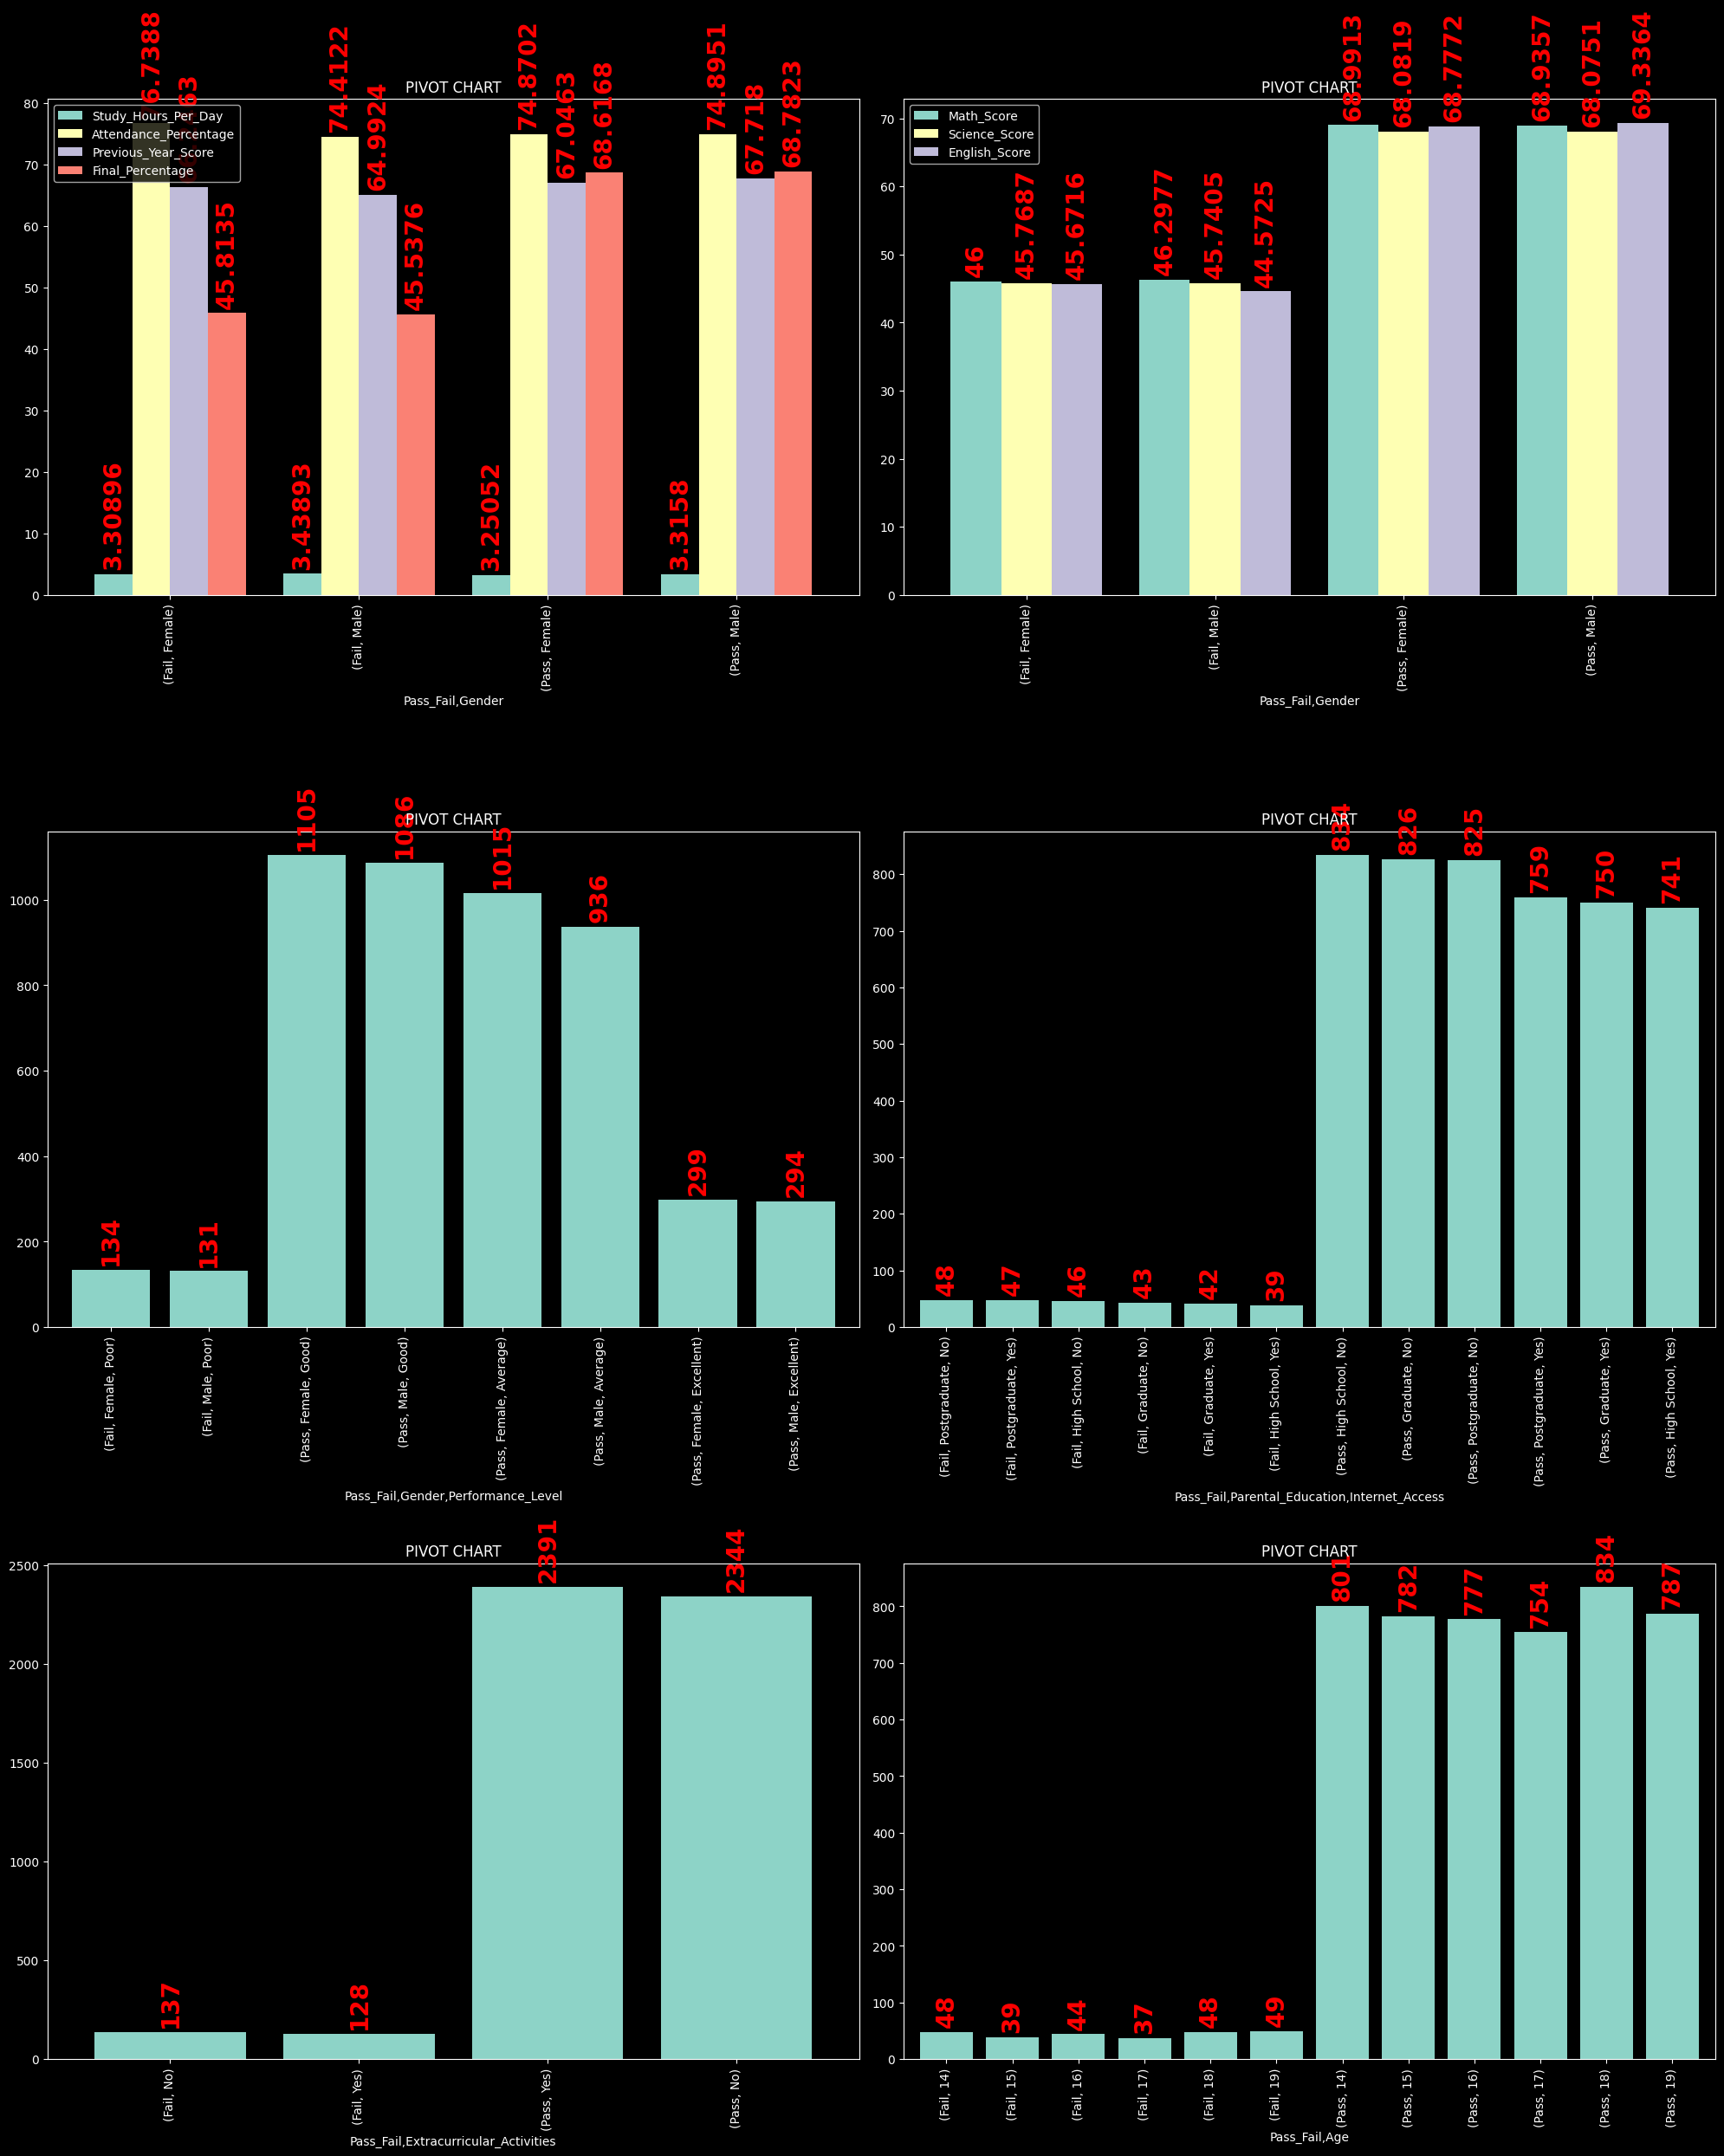

In [395]:
#  Plotting Pivot charts
fig,ax=plt.subplots(3,2,figsize=(20,25))
ax=ax.flatten()
pivot_tables=[pivot_table_1,pivot_table_2,pivot_table_3,pivot_table_4,pivot_table_5,pivot_table_6]
for i,table in enumerate(pivot_tables):
    val=table.plot(
    kind="bar",
    width=0.8,
    ax=ax[i]
    )
    for label in val.containers:
        val.bar_label(label,
                      rotation=90,
                      padding=4,
                      color="red",
                      fontsize=20,
                      fontweight="bold")
    ax[i].set_title("PIVOT CHART")
for i in range(len(pivot_tables),len(ax)):
    ax[i].axis("off")
plt.tight_layout()
plt.show()

PREPROCESSING

In [396]:
# Encode label by binary encoding
data["Pass_Fail"]=data["Pass_Fail"].replace({"Pass":1,
                                            "Fail":0},inplace=True)
data["Pass_Fail"]=data["Pass_Fail"].astype(int)

In [431]:
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import recall_score,precision_score,f1_score,confusion_matrix,ConfusionMatrixDisplay
import joblib

In [398]:
#  Separate features and label
feature=data.drop(columns="Pass_Fail")
target=data["Pass_Fail"]

In [399]:
# Split training and test data
x_train,x_test,y_train,y_test=train_test_split(
    feature,
    target,
    random_state=42,
    test_size=0.2
)

In [400]:
# Investigate splitted data
x_train.shape

(4000, 14)

In [401]:
x_test.shape

(1000, 14)

In [402]:
y_train.shape

(4000,)

In [403]:
y_test.shape

(1000,)

In [404]:
#  Create a copy of spiltted data
x_train_copy=x_train.copy()
x_test_copy=x_test.copy()

In [405]:
numerical_cols=['Age', 'Class', 'Study_Hours_Per_Day', 'Attendance_Percentage',
       'Math_Score', 'Science_Score', 'English_Score', 'Previous_Year_Score',
       'Final_Percentage']

In [406]:
categorical_cols=['Gender', 'Parental_Education', 'Internet_Access',
       'Extracurricular_Activities', 'Performance_Level']

In [407]:
# Inititae numerical pipeline
numerical_pipeline=Pipeline([
    ("missing_value",SimpleImputer(strategy="mean")),
    ("scaler",StandardScaler())
])

In [408]:
# Initiate categorical pipeline
categorical_pipeline=Pipeline([
    ("missing_value_cat",SimpleImputer(strategy='most_frequent')),
    ("encoder",OneHotEncoder(handle_unknown="ignore"))
])

In [409]:
# Combine pipelines
preprocessing=ColumnTransformer([
    ("numer",numerical_pipeline,numerical_cols),
    ("cat",categorical_pipeline,categorical_cols)
])

In [410]:
from sklearn import set_config
set_config(display="diagram")
preprocessing

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numer', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g.

In [411]:
# Initiate main pipeline
pipeline=Pipeline([
    ("preprocessor",preprocessing),
    ("model",LogisticRegression())
])

In [412]:
pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numer', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers 

TRAIN

In [413]:
pipeline.fit(x_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numer', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers 

EVALUATION AFTER TRAINING

In [422]:
y_train_predict=pipeline.predict(x_train)
cm=confusion_matrix(y_train,y_train_predict)
recall=recall_score(y_train,y_train_predict)
precision=precision_score(y_train,y_train_predict)
f1=f1_score(y_train,y_train_predict)
print(f"""Recall: {recall}
Precision: {precision}
f1_score: {f1}

Confusion Matrix 
{cm}""")

Recall: 1.0
Precision: 1.0
f1_score: 1.0

Confusion Matrix 
[[ 205    0]
 [   0 3795]]


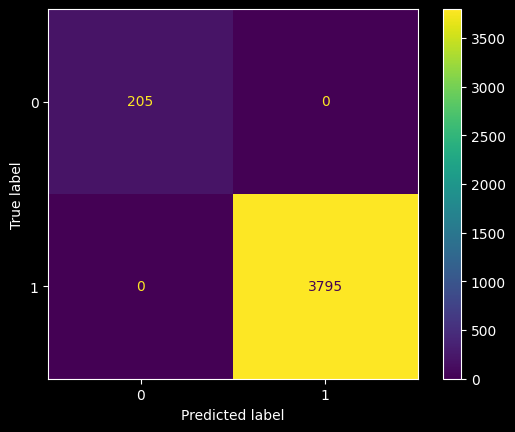

In [429]:
# Visualize confusion matrix after training
conf=ConfusionMatrixDisplay.from_predictions(y_train,y_train_predict)

TESTING

In [ ]:
y_predict=pipeline.predict(x_test)

In [423]:
cm=confusion_matrix(y_test,y_predict)
recall=recall_score(y_test,y_predict)
precision=precision_score(y_test,y_predict)
f1=f1_score(y_test,y_predict)
print(f"""Recall: {recall}
Precision: {precision}
f1_score: {f1}

Confusion Matrix 
{cm}""")

Recall: 1.0
Precision: 1.0
f1_score: 1.0

Confusion Matrix 
[[ 60   0]
 [  0 940]]


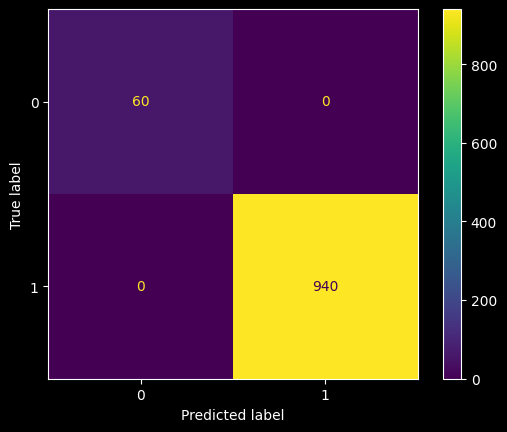

In [ ]:
#  Visualize confusion matrix
Confm_test=ConfusionMatrixDisplay.from_predictions(y_test,y_predict)

In [435]:
# Save model
joblib.dump(pipeline,"Tools/student_performance_logistic.pkl")

['Tools/student_performance_logistic.pkl']